In [8]:
import numpy as np
import pandas as pd

from sklearn.feature_extraction.text import CountVectorizer
from sklearn.preprocessing import MultiLabelBinarizer

from src import data

import matplotlib.pyplot as plt

DATA_PATH = "data/ssh_attacks.parquet"

## Experiment 1

Record settings, observations and limitations after the experiment runs.

In [2]:
# Reading the parquet file
try: 
    df = data.load_dataset(DATA_PATH)
    # display( df.isna().sum() )

    # Empty rows and empty columns
    print(f"Empty rows: {df.isna().all(axis=1).sum()}")
    print(f"Empty columns: {df.isna().all(axis=0).sum()}")

except Exception :
    print(f"An ERROR occurred while reading the dataset")

finally:
    pass


Empty rows: 0
Empty columns: 0


## Experiment 2 — Section 1.1

> Examine session lengths in characters and explicitly defined tokens, common text elements, label frequencies, label co-occurrence and label-set sizes.

Record settings, observations and limitations after the experiment runs.

### (a) Session length in characters and tokens

**Token definition:** …

**Observations:** …

In [14]:
df["n_chars"] = df["full_session"].str.len()
df["tokens"] = df["full_session"].map(data.split_tokenize)
df["n_tokens"] = df["tokens"].str.len()

display(df)

,session_id,full_session,first_timestamp,Set_Fingerprint,n_chars,tokens,n_tokens
0,0,enable ; system ; shell ; sh ; cat /proc/mount...,2019-06-04 09:45:11.151186+00:00,"[Defense Evasion, Discovery]",280,"[enable, ;, system, ;, shell, ;, sh, ;, cat, /...",62
1,1,enable ; system ; shell ; sh ; cat /proc/mount...,2019-06-04 09:45:50.396610+00:00,"[Defense Evasion, Discovery]",280,"[enable, ;, system, ;, shell, ;, sh, ;, cat, /...",62
2,2,enable ; system ; shell ; sh ; cat /proc/mount...,2019-06-04 09:54:41.863315+00:00,"[Defense Evasion, Discovery]",280,"[enable, ;, system, ;, shell, ;, sh, ;, cat, /...",62
3,3,enable ; system ; shell ; sh ; cat /proc/mount...,2019-06-04 10:22:14.623875+00:00,"[Defense Evasion, Discovery]",280,"[enable, ;, system, ;, shell, ;, sh, ;, cat, /...",62
4,4,enable ; system ; shell ; sh ; cat /proc/mount...,2019-06-04 10:37:19.725874+00:00,"[Defense Evasion, Discovery]",280,"[enable, ;, system, ;, shell, ;, sh, ;, cat, /...",62
...,...,...,...,...,...,...,...
233030,233042,cat /proc/cpuinfo | grep name | wc -l ; echo -...,2020-02-29 23:47:28.217237+00:00,"[Discovery, Persistence]",608,"[cat, /proc/cpuinfo, |, grep, name, |, wc, -l,...",116
233031,233043,cat /proc/cpuinfo | grep name | wc -l ; echo -...,2020-02-29 23:49:01.009046+00:00,"[Discovery, Persistence]",623,"[cat, /proc/cpuinfo, |, grep, name, |, wc, -l,...",116
233032,233044,cat /proc/cpuinfo | grep name | wc -l ; echo -...,2020-02-29 23:56:18.827281+00:00,"[Discovery, Persistence]",623,"[cat, /proc/cpuinfo, |, grep, name, |, wc, -l,...",116
233033,233045,cat /proc/cpuinfo | grep name | wc -l ; echo -...,2020-02-29 23:56:56.263104+00:00,"[Discovery, Persistence]",620,"[cat, /proc/cpuinfo, |, grep, name, |, wc, -l,...",116


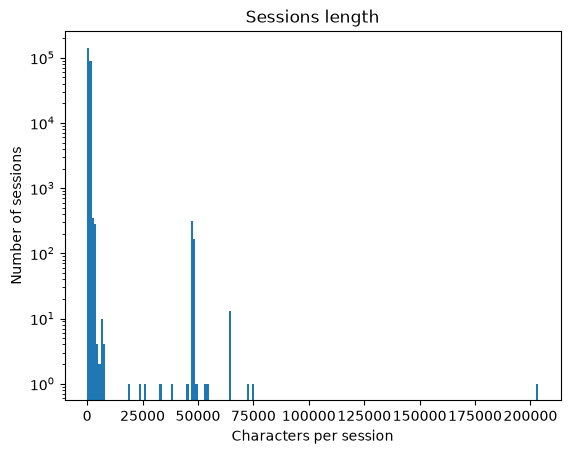

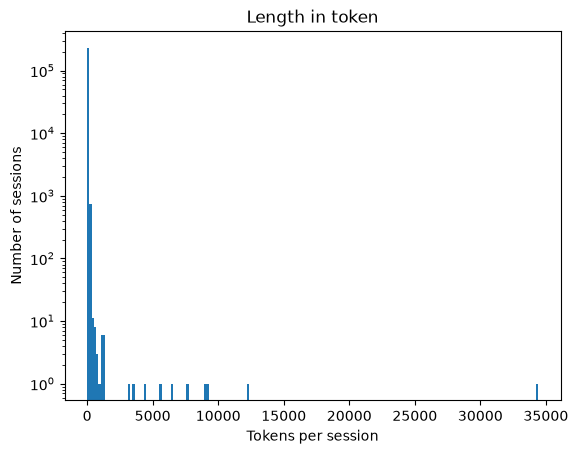

,n_chars,n_tokens
count,233035.000000,233035.000000
mean,1013.865119,120.801399
std,2282.583441,87.692157
min,3.000000,2.000000
50%,620.000000,116.000000
90%,1418.000000,138.000000
95%,1421.000000,138.000000
99%,1934.000000,161.000000
max,203442.000000,34404.000000


In [ ]:
characters = df["n_chars"]
plt.hist(characters, bins=200, log=True)
plt.xlabel("Characters per session")
plt.ylabel("Number of sessions")
plt.title("Sessions length")
plt.show()

tok = df["n_tokens"]
plt.hist(tok, bins=200,log=True)
plt.xlabel("Tokens per session")
plt.ylabel("Number of sessions")
plt.title("Length in token")
plt.show()

display(df[["n_chars", "n_tokens"]].describe(percentiles=[0.5, 0.9, 0.95, 0.99]))

### (b) Common text elements

**Observations:** …

In [ ]:
# We use CountVectorizer to build a matrix which counts the number of distinct 
# tokens for each session 
v = CountVectorizer(analyzer = lambda token : token) 
occ_token_matrix = v.fit_transform(df["tokens"])
distinct_tokens = v.get_feature_names_out()

# We build a recap token dataFrame from the occ_token_matrix 
tkn_recap = pd.DataFrame({
    "token" : distinct_tokens,
    "occurrences" : np.asarray( occ_token_matrix.sum(axis=0) ).ravel(),
    "n_sessions" : occ_token_matrix.getnnz(axis=0),
}) 
''''token' : the token string
'occurrences' : total number of times the token appears across all sessions
'n_sessions' : number of sessions that contain the token at least once '''


print('10 most common text occurrences:')
display(tkn_recap.nlargest(10, "occurrences"))

### (c) Label encoding

…

In [ ]:
# We use MultiLabelBinarizer to build a matrix where if the lable is present 
# for a session then its value is 1, otherwise it's 0
mlb = MultiLabelBinarizer(classes = data.LABELS)
Y = mlb.fit_transform(df["Set_Fingerprint"])
lsz = Y.sum(axis=1)

### (d) Label frequencies

**Observations:** …

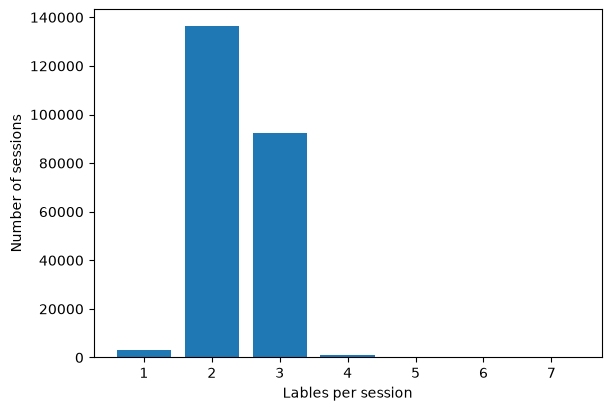

In [11]:
distribution = pd.Series(lsz).value_counts().sort_index()

fig, ax = plt.subplots(figsize=(6, 4), layout="constrained")
ax.bar(distribution.index, distribution.values)
ax.set(xlabel="Lables per session", ylabel="Number of sessions")
ax.set_xticks(distribution.index)

plt.show()

### (e) Label co-occurrence

**Observations:** …

In [12]:
# .
occurrences = pd.DataFrame(
    Y.T @ Y,
    index = mlb.classes_,
    columns = mlb.classes_,
)

display(occurrences)

,Persistence,Discovery,Defense Evasion,Execution,Impact,Other,Harmless
Persistence,211295,211281,622,91576,7,310,1950
Discovery,211281,232145,18825,92279,17,313,1968
Defense Evasion,622,18825,18999,1024,7,3,58
Execution,91576,92279,1024,92927,19,323,266
Impact,7,17,7,19,27,2,8
Other,310,313,3,323,2,327,14
Harmless,1950,1968,58,266,8,14,2206


### (f) Label-set sizes

**Observations:** …

In [13]:
display(pd.Series(lsz).value_counts().sort_index())

1      2928
2    136458
3     92571
4      1025
5        50
6         2
7         1
Name: count, dtype: int64

## Experiment 3

TODO: Plot sessions and label composition over time; define counted population and consider the November 2019 upgrade.

Record settings, observations and limitations after the experiment runs.

## Experiment 4

TODO: Define shell tokenizer rules; contrast ordinary text tokenization with shell examples.

Record settings, observations and limitations after the experiment runs.

## Experiment 5

TODO: Compare two representations including count/TF-IDF; justify normalization and consult teacher.

Record settings, observations and limitations after the experiment runs.

## Experiment 6

TODO: Inspect near-duplicate template groups and counterexamples without labels; hand groups/features to P2/P3.

Record settings, observations and limitations after the experiment runs.

## Results

TODO: insert measured tables/figures and their denominators. No results available yet.

## Interpretation and handoff

TODO: discuss limitations, uncertainty, reference agreement where relevant, and outputs needed by other developers. Update TODO.md with evidence.